# Random forest experiments

**Goal:** see whether a random forest ranks unseen subjects better than AdaBoost did (grouped AUC
about 0.55, `ada_boost.ipynb`), and which settings matter.

**Why random forest:** bagged deep trees with random feature subsets have lower variance than
boosting and are much less sensitive to noisy labels. With 670 redundant features, the per-split
feature sampling (`max_features`) also stops a few subject-specific features from dominating every
tree. Averaging many trees also gives smooth probabilities, which is what AUC scores.

**Carried over from AdaBoost:** subjects E and J are only in the test set, so we choose settings using
**GroupKFold by subject**, leave `subject` out as a feature, and test the top idea from that notebook:
**per-subject normalisation**.

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

> **Metric correction (2026-10-15).** The leaderboard scores **ROC AUC on submitted
> probabilities**, not accuracy. The leaderboard showed it: an all-1s file scored exactly 0.50000,
> which is what AUC gives any constant prediction, and our 0/1-label hybrid scored only 0.586,
> although its known-subject AUC is about 0.89. Submitting the same model's *probabilities* scored
> **0.70**. This notebook has been re-run with AUC as the metric. Models are chosen by AUC,
> submissions contain P(class 1), and threshold tuning has been removed, because AUC does not depend
> on a threshold. Some tables still show accuracy for reference.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load data

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

## 2. Preprocessing: raw and per-subject normalised features

Same raw preprocessing as the AdaBoost notebook: one-hot `state`, drop `subject` and constant columns.

The second version z-scores every numeric sensor column (`x*`, `y*`, `z*`) **within each subject**,
so the model sees each reading relative to that subject's own baseline. The mean and std come from
all of a subject's rows in train and test together. That uses no labels, and it is the only way to
normalise subjects E and J, which have no training rows.

In [3]:
target = "output"
groups = train["subject"]
y = train[target]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)

sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

def subject_zscore(X_tr, X_te):
    both = pd.concat([X_tr.assign(_s=train.subject.values), X_te.assign(_s=test.subject.values)])
    g = both.groupby("_s")[sensor_cols]
    z = (both[sensor_cols] - g.transform("mean")) / g.transform("std").replace(0, np.nan)
    both[sensor_cols] = z.fillna(0)
    both = both.drop(columns="_s")
    return both.iloc[:len(X_tr)].reset_index(drop=True), both.iloc[len(X_tr):].reset_index(drop=True)

X_norm, X_test_norm = subject_zscore(X_raw, X_test_raw)
print(f"{X_raw.shape[1]} features, {len(sensor_cols)} of them normalised per subject")

564 features, 558 of them normalised per subject


/var/folders/hr/56tdh60x4712fhss1_h0nrsc0000gn/T/ipykernel_21166/61901007.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  both = pd.concat([X_tr.assign(_s=train.subject.values), X_te.assign(_s=test.subject.values)])


## 3. Evaluation harness and majority-class baseline

The same harness as AdaBoost, with **ROC AUC** as the main metric (stratified 5-fold and GroupKFold
by subject). Accuracy and macro-F1 are kept for reference. A constant prediction scores AUC 0.5.

**Leaderboard proxy.** 54% of test rows come from unseen subjects (E, J). Our submissions give
those rows a constant score, the training class-1 rate (0.845), because no model has ranked unseen
subjects better than that (see `automl.ipynb` §7). To estimate the leaderboard AUC from training data
alone, `lb_proxy` picks 300 random groups of training subjects that together cover 45–60% of rows. It
gives their rows the constant, gives every other row the model's out-of-fold probability, and
averages the pooled AUC. Against real submissions, the proxy gave **0.753** for the submission that
scored **0.70**, and **0.720** for one that scored **0.68**. So it reads about 0.04–0.05 high, but it
puts submissions in the right order.

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X):
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["roc_auc", "accuracy", "f1_macro"], **kw)
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
    results.append(row)
    return pd.Series(row)

PRIOR = (y == 1).mean()
g_arr = np.asarray(groups, dtype=object)
_sizes = pd.Series(g_arr).value_counts()
_all = [c for r in range(3, 8) for c in itertools.combinations(sorted(_sizes.index), r)
        if 0.45 <= _sizes[list(c)].sum() / len(g_arr) <= 0.60]
_rng = np.random.default_rng(RANDOM_STATE)
proxy_subsets = [_all[i] for i in _rng.choice(len(_all), 300, replace=False)]

def lb_proxy(p_known, p_unseen=None):
    """Mean pooled AUC when ~54% of rows (random subject groups) get p_unseen (default: the
    constant PRIOR, as E/J do in our submissions) and the rest get out-of-fold p_known."""
    p_unseen = np.full(len(y), PRIOR) if p_unseen is None else np.asarray(p_unseen)
    return np.mean([roc_auc_score(y, np.where(np.isin(g_arr, s), p_unseen, p_known))
                    for s in proxy_subsets])

def within_subject_auc(p):
    """AUC inside each subject that has both classes."""
    return pd.Series({s: roc_auc_score(y[g_arr == s], p[g_arr == s])
                      for s in np.unique(g_arr) if y[g_arr == s].nunique() > 1})

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"), X_raw)

model        majority baseline
strat_auc                  0.5
strat_acc             0.844895
strat_f1m             0.457964
group_auc                  0.5
group_acc             0.852051
group_f1m              0.45784
dtype: object

## 4. Experiment 1: default random forest on raw features

**Hypothesis:** a 300-tree forest will rank rows well on stratified CV, because deep trees can
memorise subject-specific patterns, but its grouped AUC will be close to 0.5, as with AdaBoost.

In [5]:
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
evaluate("rf default, raw", rf, X_raw)

model        rf default, raw
strat_auc           0.732604
strat_acc           0.853403
strat_f1m           0.526932
group_auc           0.536172
group_acc           0.848169
group_f1m           0.461232
dtype: object

**Interpretation:** the hypothesis held. Stratified AUC is **0.733**, but grouped AUC is only
**0.536**. The forest ranks rows well for subjects it has seen and barely for new ones.

## 5. Experiment 2: per-subject normalisation

**Hypothesis:** if the raw features mostly encode *who* the subject is, z-scoring within subject
removes that and leaves the within-subject changes that relate to the class. Grouped AUC should rise
above 0.5, and the gap between stratified and grouped CV should shrink.

In [6]:
evaluate("rf default, subject-norm", rf, X_norm)
pd.DataFrame(results).set_index("model").round(4)

,strat_auc,strat_acc,strat_f1m,group_auc,group_acc,group_f1m
model,,,,,,
majority baseline,0.5000,0.8449,0.4580,0.5000,0.8521,0.4578
"rf default, raw",0.7326,0.8534,0.5269,0.5362,0.8482,0.4612
"rf default, subject-norm",0.8632,0.8661,0.6631,0.5801,0.8433,0.4649


**Interpretation:** the hypothesis held, and **this reverses what we concluded under accuracy.**
Per-subject normalisation raises grouped AUC from 0.536 to **0.580**, and stratified AUC from 0.733
to **0.863**. Under accuracy it looked like it hurt (grouped accuracy 0.848 → 0.843), because the
forest still predicted almost all 1s. AUC shows the ranking improved. The rest of the notebook uses
the normalised features, chosen automatically by grouped AUC.

## 6. Experiment 3: tune `max_features` and `min_samples_leaf`

**Hypothesis:** with hundreds of redundant features, `max_features` matters most. Fewer features per
split means less correlated trees. Larger leaves smooth the probability estimates and should help on
unseen subjects. We tune on **grouped AUC**, using the feature set from Experiment 2 with the higher
grouped AUC.

In [7]:
best_rep = max(["raw", "subject-norm"],
               key=lambda r: pd.DataFrame(results).set_index("model").loc[f"rf default, {r}", "group_auc"])
X_best, X_test_best = (X_norm, X_test_norm) if best_rep == "subject-norm" else (X_raw, X_test_raw)
print("Using features:", best_rep)

grid = []
for mf in ["sqrt", 0.1, 0.3]:
    for leaf in [1, 5, 20]:
        m = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=leaf,
                                   n_jobs=-1, random_state=RANDOM_STATE)
        s = cross_validate(m, X_best, y, cv=gkf, groups=groups, n_jobs=-1, scoring=["roc_auc", "accuracy"])
        grid.append({"max_features": mf, "min_samples_leaf": leaf,
                     "group_auc": s["test_roc_auc"].mean(), "group_acc": s["test_accuracy"].mean()})
grid = pd.DataFrame(grid)
grid.pivot(index="max_features", columns="min_samples_leaf", values="group_auc").round(4)

Using features: subject-norm


min_samples_leaf,1,5,20
max_features,,,
0.1,0.5640,0.5883,0.5495
0.3,0.5247,0.5271,0.5102
sqrt,0.5801,0.5726,0.5481


In [8]:
best = grid.loc[grid.group_auc.idxmax()]
best_params = {"max_features": best.max_features, "min_samples_leaf": int(best.min_samples_leaf)}
print("Best:", best_params)
rf_best = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
rf_row = evaluate(f"rf tuned {best_params}, {best_rep}", rf_best, X_best)
rf_row

Best: {'max_features': 0.1, 'min_samples_leaf': 5}


model        rf tuned {'max_features': 0.1, 'min_samples_le...
strat_auc                                             0.862774
strat_acc                                             0.866931
strat_f1m                                             0.664246
group_auc                                              0.58098
group_acc                                             0.848652
group_f1m                                              0.46339
dtype: object

**Interpretation:** `max_features` matters most, as expected. A fraction of 0.1 (about 56 features
per split) is best, at **0.588** with leaf size 5. `sqrt` (about 24 features) is close behind, and
0.3 is clearly worse (0.51–0.53). Leaf size shows no consistent trend. The gain from tuning (+0.008
over the default forest) is small next to the noise between folds.

## 7. Experiment 4: extremely randomised trees

**Hypothesis:** Extra Trees picks split thresholds at random, which reduces variance more than a
random forest does. If the remaining problem is overfitting individual subjects, Extra Trees should
do slightly better on grouped AUC.

In [9]:
et = ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
et_row = evaluate(f"extra trees {best_params}, {best_rep}", et, X_best)
pd.DataFrame(results).set_index("model").round(4)

,strat_auc,strat_acc,strat_f1m,group_auc,group_acc,group_f1m
model,,,,,,
majority baseline,0.5000,0.8449,0.4580,0.5000,0.8521,0.4578
"rf default, raw",0.7326,0.8534,0.5269,0.5362,0.8482,0.4612
"rf default, subject-norm",0.8632,0.8661,0.6631,0.5801,0.8433,0.4649
"rf tuned {'max_features': 0.1, 'min_samples_leaf': 5}, subject-norm",0.8628,0.8669,0.6642,0.5810,0.8487,0.4634
"extra trees {'max_features': 0.1, 'min_samples_leaf': 5}, subject-norm",0.8787,0.8647,0.6430,0.5914,0.8503,0.4572


**Interpretation:** consistent with the hypothesis. Extra Trees reaches a grouped AUC of **0.591**
vs 0.581 for the tuned forest, and a stratified AUC of 0.879 vs 0.863. The grouped gain is within
noise. It is the best unseen-subject model in this notebook.

## 8. Experiment 5: pooled vs within-subject ranking on unseen subjects

**Hypothesis:** the leaderboard computes one **pooled** AUC over all test rows, so a model has to get
two things right: the *order* of rows inside each subject, and the *level* of its scores across
subjects. A model can do the first and fail the second. We expect some within-subject ranking
(AUC a bit above 0.5) but a pooled grouped AUC near or below 0.5, because the forest can't know an
unseen subject's class-0 rate.

In [10]:
final_model = et if et_row.group_auc > rf_row.group_auc else rf_best
print("Model:", type(final_model).__name__)

oof = cross_val_predict(final_model, X_best, y, cv=gkf, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
within = within_subject_auc(oof)
print(f"Pooled out-of-fold grouped AUC: {roc_auc_score(y, oof):.3f}")
print(f"Mean within-subject AUC:        {within.mean():.3f}")
within.round(3).rename("within-subject AUC (subject unseen)").to_frame().T

Model: ExtraTreesClassifier


Pooled out-of-fold grouped AUC: 0.389
Mean within-subject AUC:        0.568


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (subject unseen),0.804,0.609,0.483,0.593,0.534,0.533,0.345,0.704,0.571,0.5


**Interpretation:** the hypothesis held strongly. Within each unseen subject, Extra Trees ranks rows
somewhat: mean within-subject AUC **0.568** (A 0.80, I 0.70, B 0.61, but H 0.35). But the pooled
out-of-fold AUC is only **0.389**, well below chance. The fold-averaged grouped AUC of 0.59 in §7
falls in between, because each fold mixes only 2–3 subjects. So the ranking inside a subject is
partly real, but the score levels across subjects are wrong.

## 9. Do score levels track each subject's class-0 rate?

**Hypothesis:** for a subject the model hasn't seen, its average predicted P(class 1) won't match
that subject's real class-1 rate. That would explain any gap between pooled and within-subject AUC.

In [11]:
levels = pd.DataFrame({"mean_pred_p1": pd.Series(oof).groupby(g_arr).mean(),
                       "true_rate_1": (y == 1).groupby(g_arr).mean()})
print(f"Correlation across subjects between mean predicted P(class 1) and true class-1 rate: "
      f"{levels.corr().iloc[0, 1]:.2f}")
levels.round(3).T

Correlation across subjects between mean predicted P(class 1) and true class-1 rate: -0.49


,A,B,C,D,F,G,H,I,K,L,M
mean_pred_p1,0.788,0.898,0.856,0.710,0.871,0.865,0.884,0.849,0.803,0.803,0.863
true_rate_1,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709


**Interpretation:** the hypothesis held, and the levels go the wrong way: the correlation is
**−0.49**. Subjects with *more* class 0 tend to get *higher* P(class 1). For example, G's true
class-1 rate is 0.49 but its mean prediction is 0.87; D's is 0.94 vs 0.71. This is why pooled AUC
falls below 0.5, and why our submissions give E and J a constant instead of model probabilities
(`automl.ipynb` §7).

## 10. Feature importance

The grade includes 10% for explainability. As in the AdaBoost notebook, we compare:
- **Impurity importance** (`feature_importances_`): averaged over all trees, but biased toward
  high-cardinality features.
- **Permutation importance** on held-out subjects: the drop in **AUC** when a feature is shuffled.

**Hypothesis:** the features the forest splits on most (impurity) won't be the ones that matter on
unseen subjects (permutation), because the strong features separate subjects, not classes.

Held-out subjects: ['C', 'I']


Top-20 overlap: ['x40', 'x47', 'y46', 'z47']


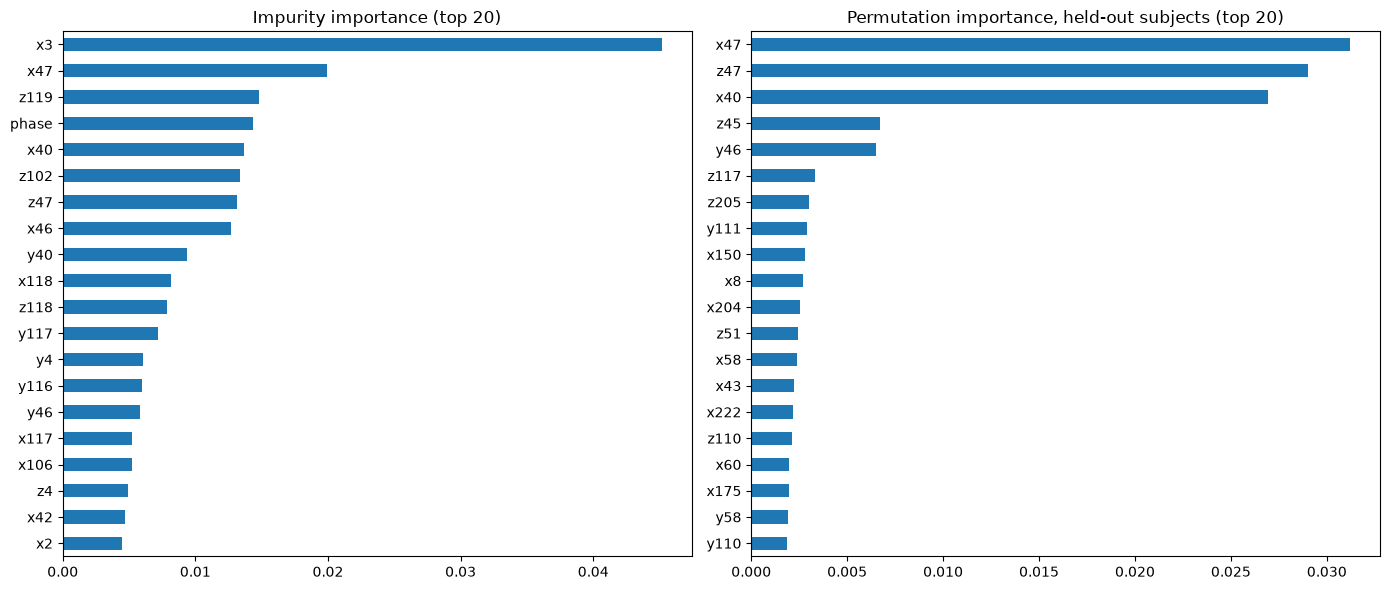

In [12]:
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))
final_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])

imp = pd.Series(final_model.feature_importances_, index=X_best.columns).sort_values(ascending=False)
perm = permutation_importance(final_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance, held-out subjects (top 20)")
plt.tight_layout()
print("Top-20 overlap:", sorted(set(imp.head(20).index) & set(perm_imp.head(20).index)))

**Interpretation:** partly wrong. Unlike AdaBoost, the two views now share features: 4 of the top
20 are in both lists (`x40`, `x47`, `y46`, `z47`).
- By permutation on held-out subjects C and I, three features stand out: `x47` (0.031 AUC), `z47`
  (0.029) and `x40` (0.027). Everything else is ≤ 0.007.
- By impurity, `x3` leads (0.045), followed by `x47`, `z119`, `phase` and `x40`.

`x40` and `z47` are also the top features of the known-subject gradient boosting model
(`gradient_boosting.ipynb` §8). After per-subject normalisation, these features carry within-subject
signal that transfers, at least to C and I. They are the best candidates for an unseen-subject
model.

## 11. Fit on all training data and write a submission (probabilities)

In [13]:
final_model.fit(X_best, y)
submission = sample_solution.copy().astype({"output": float})
submission["output"] = final_model.predict_proba(X_test_best)[:, 1]
submission.to_csv("submission_random_forest_proba.csv", index=False)
submission.output.describe().round(3)

count    1732.000
mean        0.840
std         0.122
min         0.085
25%         0.806
50%         0.857
75%         0.913
max         0.999
Name: output, dtype: float64

## 12. Experiment 6: hybrid model (known subjects vs unseen subjects)

Section 5 showed that per-subject normalisation gives a strong ranking *within* subjects the model
has seen (stratified AUC 0.86), and §8–9 showed that score levels for unseen subjects are wrong. The
test set mixes both kinds of row, so we treat them separately:
- **Rows from subjects A–M** (also in training): use the per-subject normalised forest's
  probabilities.
- **Rows from E and J** (test only): give them a constant, the training class-1 rate. That is the
  safest choice when the model can't place an unseen subject's level (`automl.ipynb` §7).

First we check that stratified CV is a fair way to score the known-subject rows. That is only true if
those test rows look like a random sample of each subject's data, not a separate later session.

In [14]:
known = test.subject.isin(train.subject.unique()).values
test_known = test[known]
print(f"Test rows from known subjects: {known.mean():.1%} ({known.sum()} rows)")
pd.concat({
    "train": train.phase.value_counts(normalize=True),
    "test, known subjects": test_known.phase.value_counts(normalize=True),
}, axis=1).sort_index().round(3)

Test rows from known subjects: 45.7% (791 rows)


,train,"test, known subjects"
phase,,
1,0.265,0.248
2,0.232,0.220
3,0.221,0.225
4,0.282,0.307


**Interpretation:** the `phase` mix (and the `state` mix) of known-subject test rows matches
training to within about 2 points. Those rows look like a random sample of the same recordings, so
stratified CV is a reasonable estimate for this part of the test set.

**Hypothesis:** for known subjects, (a) the subject-normalised forest ranks rows much better than
chance, and (b) adding the subject itself as a feature (one-hot) helps further. Class-0 rates range
from 0% (K) to 51% (G), and for known subjects that rate can be learned. Under a pooled AUC, knowing
each subject's level is worth a lot.

We score candidates with stratified out-of-fold **AUC** and the **leaderboard proxy** (§3).

In [15]:
subj_cols = sorted(train.subject.unique())
def subject_onehot(df):
    return pd.get_dummies(df.subject, prefix="subj", dtype=int).reindex(
        columns=[f"subj_{s}" for s in subj_cols], fill_value=0).reset_index(drop=True)

candidates = {
    "subject-norm": (X_norm, X_test_norm),
    "subject-norm + subject id": (pd.concat([X_norm, subject_onehot(train)], axis=1),
                                  pd.concat([X_test_norm, subject_onehot(test)], axis=1)),
}
rf_known = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
oof_known = {name: cross_val_predict(rf_known, X, y, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
             for name, (X, _) in candidates.items()}

known_results = pd.DataFrame(
    {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))}}
    | {name: {"auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)} for name, p in oof_known.items()}).T
known_results.round(4)

,auc,lb_proxy
constant (all rows),0.5000,0.5000
subject-norm,0.8649,0.7326
subject-norm + subject id,0.8650,0.7352


In [16]:
best_known = known_results.drop("constant (all rows)").lb_proxy.idxmax()
print(f"Best for known subjects: {best_known}")
pd.DataFrame({name: within_subject_auc(p) for name, p in oof_known.items()}).round(3).T

Best for known subjects: subject-norm + subject id


,A,B,C,D,F,G,H,I,L,M
subject-norm,0.842,0.804,0.662,0.572,0.782,0.692,0.580,0.804,0.861,0.78
subject-norm + subject id,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.860,0.78


**Interpretation:** both parts held, but (b) only just. Out-of-fold AUC is **0.865** for both feature
sets. The subject id adds +0.003 to the leaderboard proxy (0.7352 vs 0.7326) and a little
within-subject AUC for most subjects, so it is chosen. Within-subject AUC is highest for L (0.86), A,
B and I (0.81–0.85), M and F (0.78), and lowest for D (0.56) and H (0.55).

## 13. Hybrid submission (probabilities)

Fit the best known-subject model on all of the training data and write its probabilities for the
known-subject test rows. E and J rows get the constant training class-1 rate.

In [17]:
X_fit, X_test_fit = candidates[best_known]
rf_known.fit(X_fit, y)
hybrid = sample_solution.copy().astype({"output": float})
hybrid["output"] = PRIOR
hybrid.loc[known, "output"] = rf_known.predict_proba(X_test_fit[known])[:, 1]
hybrid.to_csv("submission_hybrid_proba.csv", index=False)
print(f"E/J rows: constant {PRIOR:.3f}")
hybrid.output[known].groupby(test_known.subject.values).mean().round(3).rename("mean P(class 1), known subjects")

E/J rows: constant 0.845


A    0.946
B    0.863
C    0.754
D    0.918
F    0.746
G    0.492
H    0.781
I    0.939
K    0.961
L    0.905
M    0.746
Name: mean P(class 1), known subjects, dtype: float64

**Interpretation:** the mean predicted P(class 1) for each known subject closely tracks that
subject's training class-1 rate (G 0.49 vs 0.49, C 0.75 vs 0.76, K 0.96 vs 1.00). That is what a
pooled AUC needs, and it is the opposite of what happens for unseen subjects (§9). E and J get 0.845.
The leaderboard proxy is **0.735**, below the Extra Trees hybrid in `automl.ipynb` (proxy 0.75,
public 0.70), so this file isn't worth a submission. Its 0/1 version, `submission_hybrid.csv`, scored
0.579.

## Summary and next steps

**Result (AUC):**

| Model | Stratified AUC | Grouped AUC (unseen subjects) |
|---|---|---|
| constant | 0.500 | 0.500 |
| forest, raw features | 0.733 | 0.536 |
| forest, per-subject normalised | 0.863 | 0.580 |
| forest tuned (`max_features=0.1`, leaf 5) | 0.863 | 0.581 |
| **Extra Trees**, same settings | **0.879** | **0.591** |

**Hybrid (known subjects):** out-of-fold AUC 0.865, leaderboard proxy 0.735.

**What we learned:**
- **Per-subject normalisation helps on unseen subjects under AUC** (0.536 → 0.58–0.59 grouped). We had
  recorded the opposite under accuracy.
- But the score *levels* for unseen subjects go the wrong way (correlation −0.49 with their true
  class-1 rates). Pooled grouped AUC is 0.39 even though within-subject AUC is 0.57. The leaderboard
  computes a pooled AUC, so model probabilities for E and J would hurt. A constant is safer.
- `x47`, `z47` and `x40` carry the within-subject signal that transfers to held-out subjects.

**Next steps:**
1. Give E and J the constant *level*, but order rows inside each of them by this normalised Extra
   Trees model (for example 0.845 + a small multiple of the within-subject rank). That would use the
   0.57 within-subject AUC without the wrong levels. It hasn't been tested yet.
2. Explain `x47`, `z47` and `x40` with SHAP or per-subject plots, for the explainability part of the
   grade.

*Runtime:* about 5 minutes.